# **Decision Trees For Classification on the Iris Dataset**

In [ ]:
import pandas as pd

Imported pandas so I will be able to work with table in python

In [ ]:
df= pd.read_csv("1__iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


read the uploaded documents and I viewed the first 5 rows



In [ ]:
df.shape

(150, 5)

Tell us the shape of the dataset

It has 150 rows and 5 colums

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


asked for more information on the dataframe.
It shows I have 150 entries


In [ ]:
df.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


checked through the dataframe if there is  null input and sums it up.It shows that there is no empty input.

In [ ]:
df.duplicated().sum()

np.int64(3)

checks if there are duplicates. There are 3 duplicated rows

In [ ]:
df= df.drop_duplicates()
df.shape

(147, 5)

dropped all the duplicated rows because a repeated row would make the model count the same flower twice.

Now the rows has reduced to 147 because the duplicated rows were dropped

In [ ]:
df["species"].value_counts()

,count
species,
versicolor,50
virginica,49
setosa,48


Counts the value of each species

In [ ]:
X = df.drop("species",axis=1)
y = df["species"]
X.shape

(147, 4)

X is the input of each rows
y is the target (what we want to find out after knowing all the input is X)
species were left as text because it makes the reports easy to read



In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=0.2, random_state = 42, stratify=y)
print(X_train.shape, X_test.shape)

(117, 4) (30, 4)


imported train_test_split from scikit learn and split my X and y into train and test .
20% of the whole data frame was my test data and I made my random state to be 42 so that it is repeatable
and I stratify y so that there will be an even distrubution of all the species.


In [ ]:
print(y_train.value_counts())
print(y_test.value_counts())

species
versicolor    40
virginica     39
setosa        38
Name: count, dtype: int64
species
versicolor    10
virginica     10
setosa        10
Name: count, dtype: int64


counts the values of the y_train and y_test dataset

In [ ]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state =42)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)

I imported DecisionTreeClassifier form scikit Learn
Made a DecisionTreeClassifier model with a random state of 42 so that it is repeatable and named it tree
Fit(studied) the train datasets(X and y)
made the model(tree) predict the answer to the test dataset and named it y_pred

In [ ]:
from sklearn.metrics import accuracy_score
print(tree.get_depth(), tree.get_n_leaves())
print(tree.score(X_train,y_train))
print(accuracy_score(y_test,y_pred))

5 8
1.0
0.9333333333333333


get_depth the the longest chain from the root to the answer
get_n_leaves is the number of final answer boxes
tree.score measures the accuracy on the train dataset
accuracy_score calculates the accuracy of the predicted answer with the real answer
The longest chain was 5, 8 leaves, the trainig accuracy was 1 which means the flowers were studied right, and the test accuracy was 0.93 or 93.3% which means it got 28 right and 2 wrong

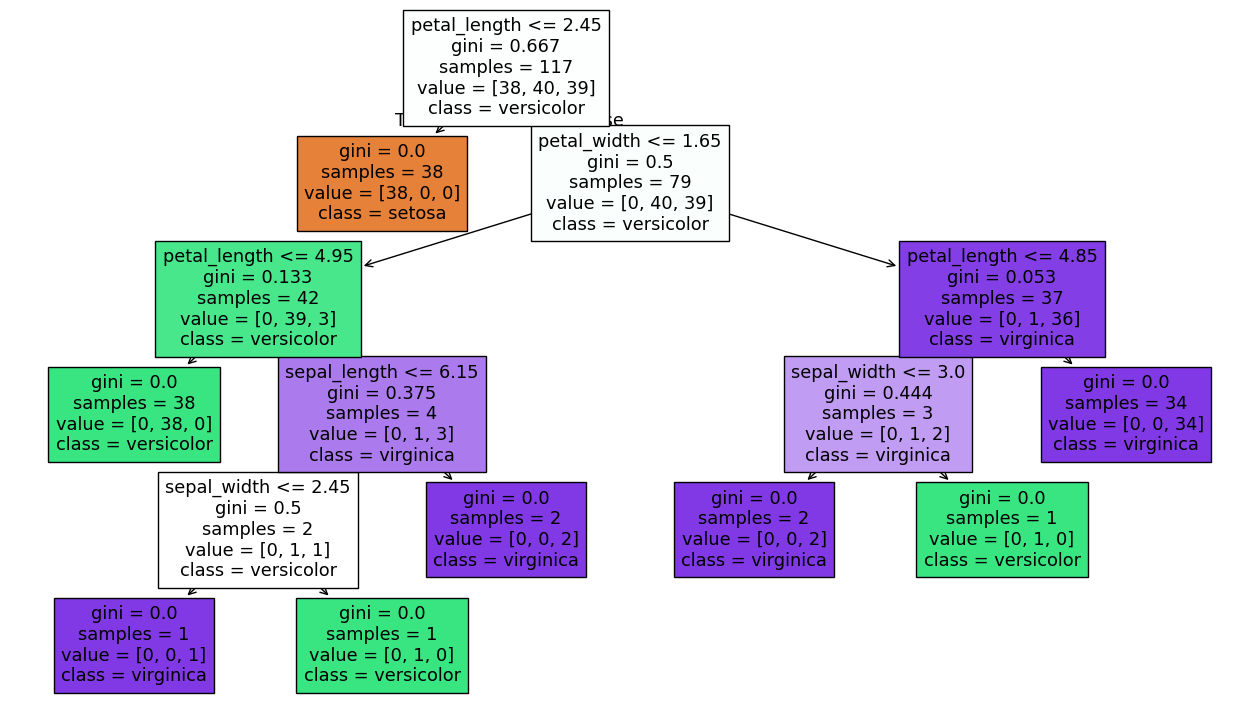

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure (figsize=(16, 9))
plot_tree(tree, feature_names=X.columns, class_names =tree.classes_, filled=True)
plt.show()

I loaded  the charting Library with the nickname plt

plt.figure.... makes the drawing large 16 by 9 inches so the text can be readable

plot_tree(tree, ...) draws the tree that has been trained
feature_names=X.columns labels each question with the real column name, and class_names=tree.classes_ labels the answers with the species names (setosa, versicolor, virginica, in alphabetical order). filled=True colours each box by its majority species, and a darker colour means a purer box.
plt.show() displays the finished picture.

In [ ]:
from sklearn.tree import export_text
print(export_text(tree, feature_names=list(X.columns)))

|--- petal_length <= 2.45
|   |--- class: setosa
|--- petal_length >  2.45
|   |--- petal_width <= 1.65
|   |   |--- petal_length <= 4.95
|   |   |   |--- class: versicolor
|   |   |--- petal_length >  4.95
|   |   |   |--- sepal_length <= 6.15
|   |   |   |   |--- sepal_width <= 2.45
|   |   |   |   |   |--- class: virginica
|   |   |   |   |--- sepal_width >  2.45
|   |   |   |   |   |--- class: versicolor
|   |   |   |--- sepal_length >  6.15
|   |   |   |   |--- class: virginica
|   |--- petal_width >  1.65
|   |   |--- petal_length <= 4.85
|   |   |   |--- sepal_width <= 3.00
|   |   |   |   |--- class: virginica
|   |   |   |--- sepal_width >  3.00
|   |   |   |   |--- class: versicolor
|   |   |--- petal_length >  4.85
|   |   |   |--- class: virginica



This is the same tree just as plain text

export_text writes the tree as indented lines.The indentation shows how deep one is

In [ ]:
for d in[1, 2,3,4,5]:
  t= DecisionTreeClassifier(max_depth=d,random_state=42)
  t.fit(X_train, y_train)
  print(d, t.get_n_leaves(),t.score(X_train,y_train),t.score(X_test,y_test))

1 2 0.6666666666666666 0.6666666666666666
2 3 0.9658119658119658 0.9333333333333333
3 5 0.9829059829059829 0.9666666666666667
4 7 0.9914529914529915 0.9333333333333333
5 8 1.0 0.9333333333333333


Created a for loop d that tries each depth from from 1 to 5
Made t my DecisionTreeClassifier with maximum depth of d  and also gives it a random state of 42 (which makes it repeatable)
fit(studided) my train dataset
So for each one it trains a tree and prints the depth, the training accuracy and the test accuracy
Check through the result:
for depth 1 it shows that the training accuracy and the test accuracy are both the same :0.6666 at this depth the tree can only ask one question, so it seperates setosa and puts the other two species together

for depth 2 the training accuracy was 0.966 but the test accuracy was 0.933

at depth 3 the training accuracy was 0.983 and the test accuracy was 0.967. After this overfitting sets in  

at depth 4 the training accuracy was 0.991 and the test accuracy was 0.933

at depth 5 the training accuracy was 1.0 and the test accuracy was 0.933

depth 3 gets nearly every thing right and after that even though the training accuracy was creeping to 100% the test accuracy did not improve anymore

so depth 3 is a sensible choice of depth for purning




In [ ]:
pruned = DecisionTreeClassifier(max_depth=3, random_state=42)
pruned.fit(X_train, y_train)
print(pruned.get_depth(), pruned.get_n_leaves())
print(pruned.score(X_train, y_train))
print(pruned.score(X_test, y_test))

3 5
0.9829059829059829
0.9666666666666667


same step as before just that now  we made our depth 3

In [ ]:
from sklearn.metrics import f1_score, classification_report
y_pred_pruned = pruned.predict(X_test)
print(accuracy_score(y_test, y_pred_pruned))
print(f1_score(y_test, y_pred_pruned, average="macro"))
print(classification_report(y_test, y_pred_pruned))

0.9666666666666667
0.9665831244778612
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



predict on the test dataset with the purned tree, then calculates the accuracy,F1 and the classification report

As we know now that the accuracy is 0.967 which means it got 29 out of 30 spieces of flower right.
It's f1 score was also 0.967 and in the report setosa is 1 on everything and versicolot and virginica are each about 0.95



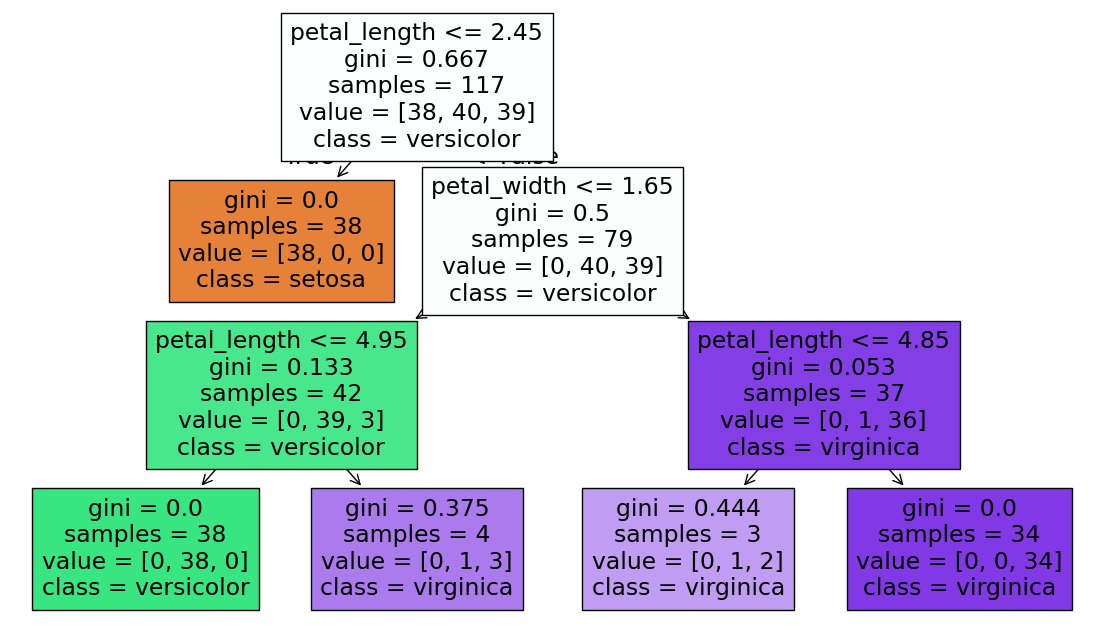

In [ ]:
plt.figure(figsize=(14,8))
plot_tree(pruned,feature_names=X.columns,class_names=pruned.classes_, filled=True)
plt.show()

This is the same drawing code as before,using "pruned" instead of tree.

In [ ]:
from sklearn.metrics import f1_score, classification_report
y_pred_pruned = pruned.predict(X_test)
print(accuracy_score(y_test, y_pred_pruned))
print(f1_score(y_test, y_pred_pruned, average="macro"))
print(classification_report(y_test, y_pred_pruned))

0.9666666666666667
0.9665831244778612
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



predict on the test dataset with the purned tree, then calculates the accuracy,F1 and the classification report

As we know now that the accuracy is 0.967 which means it got 29 out of 30 species of flower right.
It's f1 score was also 0.967 and in the report setosa is 1 on everything and versicolor and virginica are each about 0.95


In [ ]:
pd.Series(pruned.feature_importances_, index=X.columns)

,0
sepal_length,0.000000
sepal_width,0.000000
petal_length,0.574498
petal_width,0.425502


This shows the decision of the pruned dataset.
It shows how much each column was used
It used about 0.57 petal length and it also used 0.43 petal width the sepal columns were 0
which means the tree only needed the two petal measurements